# Trace a synthetic street route and name its assumptions

**Learning question:** Which shortest path does breadth-first search find in a small unweighted street graph?

Seven complete standard-library lessons connect streets, urban graphs, contextual summaries, synthetic imagery labels, visualisation and reproducible exports.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

Treat each undirected edge as one traversable connection. Breadth-first search visits routes in increasing edge count; alphabetical neighbour order makes ties reproducible. This is a synthetic topological graph, with no street geometry, travel times, direction, accessibility or real OSM evidence.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic graph: 6 nodes; 8 edges
Deterministic shortest route: A -> B -> C -> F ; edges: 3
Synthetic street-node degrees | undirected connections: {'A': 2, 'B': 4, 'C': 2, 'D': 3, 'E': 3, 'F': 2}


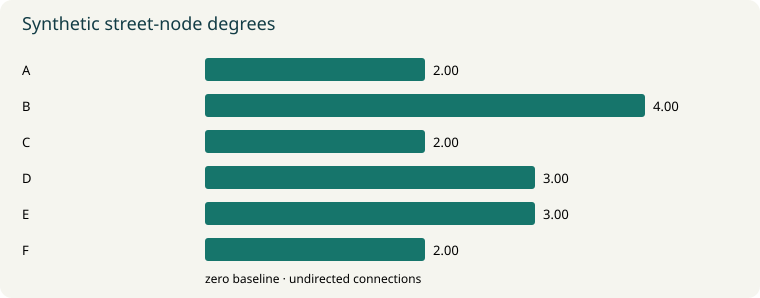

In [2]:
from collections import deque
edges = [('A','B'),('A','D'),('B','C'),('B','D'),('B','E'),('C','F'),('D','E'),('E','F')]
graph = {node:set() for edge in edges for node in edge}
for left,right in edges:
    graph[left].add(right);graph[right].add(left)
queue = deque([['A']]);visited = {'A'}
while queue:
    route = queue.popleft()
    if route[-1] == 'F':
        break
    for neighbor in sorted(graph[route[-1]]):
        if neighbor not in visited:
            visited.add(neighbor);queue.append(route+[neighbor])
else:
    raise ValueError('No synthetic route from A to F exists; the search is exhausted.')
degrees = {node:len(graph[node]) for node in sorted(graph)}
print('Synthetic graph:', len(graph), 'nodes;', len(edges), 'edges')
print('Deterministic shortest route:', ' -> '.join(route), '; edges:', len(route)-1)
bars(degrees, 'Synthetic street-node degrees', 'undirected connections')


## Interpret the result

The graph has six nodes and eight edges. Degrees are A2, B4, C2, D3, E3, F2; the deterministic route A → B → C → F has three edges. Other equal-length paths may exist. Highest degree is neither best service access nor social importance. Invented labels and topology do not describe any real neighbourhood.

## Change one thing

Remove B–C, rerun and compare the route. Add edge lengths only after replacing BFS with an appropriate weighted method. In the source urban-context lesson keep building area, population and zone area as separate quantities. Explain why the graph-ML held-out error is useful evidence rather than hiding it.


## Source course and scientific boundaries

All seven notebooks retain the authoritative source TOC order and the sibling notebooks/_static relation for the pipeline illustration. Executable source cells use only standard-library Python; they do not import Urbanity. The three local SVGs are original vector teaching artwork. Native Urbanity installation, OSM acquisition, compiled geospatial dependencies, imagery credentials and optional graph ML remain explicitly linked continuations.

[Complete local course guide](../../courses/urbanity/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-Urbanity/blob/a9d2b1e0d0af91dc2782f7f1d77d9bbb10c67d0f/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-Urbanity)

Owner-authorized original source companion; this source repository has no public license grant, and the MIT license of the separate Urbanity software package does not relicense it. Synthetic diagrams, graph records and imagery labels are not provider data. Independent companion with no Urbanity endorsement. Retain Yap, Stouffs & Biljecki (2023), DOI 10.1038/s42949-023-00125-w; streetscape DOI 10.1177/23998083221138832; global networks DOI 10.1038/s41597-023-02578-1; urban graphs DOI 10.17605/OSF.IO/ABYQH; conditional building-carbon reference DOI 10.1038/s41893-025-01615-8. Each external dataset/provider retains separate terms.

- [Read source Book](https://jltobias.github.io/JupyterLite-Urbanity/) — Source-route reviewed; HTTP entry not freshly checked
- [Run source Lab](https://jltobias.github.io/JupyterLite-Urbanity/lab/lab/index.html?path=notebooks/street-networks.ipynb) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic urban map](https://jltobias.github.io/JupyterLite-Urbanity/exhibits/2d-map.html) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic urban heights](https://jltobias.github.io/JupyterLite-Urbanity/exhibits/3d-map.html) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic urban scene](https://jltobias.github.io/JupyterLite-Urbanity/exhibits/3d-scene.html) — Source-route reviewed; HTTP entry not freshly checked

[Central references](../../references.ipynb)


## Browser GIS pathway

**Geographic question:** Which assumptions are lost when a synthetic unweighted street graph is drawn as a geographic network?

**Data readiness (O; N continuation):** Seven standard-library lessons use synthetic graph/context/imagery-label records without real OSM, provider imagery or Urbanity package execution. No public repository license is inferred.

**Start from the chapter evidence:** [street graph](../../courses/urbanity/notebooks/street-networks.ipynb) · [urban context](../../courses/urbanity/notebooks/urban-context.ipynb) · [held-out graph exercise](../../courses/urbanity/notebooks/graph-ml.ipynb)

- **[RustGIS Web](https://web.rustgis.app/):** Use a declared synthetic geographic graph only if coordinates and a CRS are explicitly added; preserve its invented status and compare six nodes/eight edges. Topological labels alone are not geographic data.
- **[GeoLibre Web](https://web.geolibre.app/):** Compare the same synthetic nodes and route A–B–C–F in a second view; record differences between edge count and distance. Native Urbanity/OSM/imagery work needs its own licensed inputs and environment.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Explain how degree and unweighted shortest paths can misrepresent accessibility using the supplied synthetic node IDs. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** The source toy held-out classification is a learning exercise; real urban graph ML needs independent places, defensible labels and leakage checks. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Keep six node IDs, eight edge pairs, route tie-breaking, synthetic labels and owner-authorized source scope visible. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
